# B - Vegetation, tussocks, volume and biomass (B1-B4)

In [1]:
import sys; sys.path.insert(0, "..")            # so the notebook finds helpers.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import helpers as H

EP = H.epochs()                                  # all epochs found in data/merged
R = {e: H.process(e) for e in EP}                # ground / vegetation separation: slow the first time, cached afterwards
print([H.EPOCH_LABEL[e] for e in EP])
E = "20250327" if "20250327" in EP else EP[-1]       # epoch of the manual biomass samples
r = R[E]; t = H.tussocks(r)                          # one row per tussock

['Feb 2024', 'May 2024', 'Jun 2024', 'Jul 2024', 'Mar 2025', 'May 2025', 'Feb 2026', 'Oct 2026']


## B1 - Vegetation / ground separation applied to the study area

In [2]:
data_m2 = H.has_data(r).sum() * H.FINE_RES ** 2
print(f"Vegetation points: {100 * r['n_veg'] / r['n_points']:.2f} % of all points")
print(f"Vegetation cover: {H.cover_m2(r):.1f} m2 = {100 * H.cover_m2(r) / data_m2:.2f} % of the {data_m2:.0f} m2 that has LiDAR data")

Vegetation points: 0.66 % of all points
Vegetation cover: 433.4 m2 = 0.86 % of the 50600 m2 that has LiDAR data


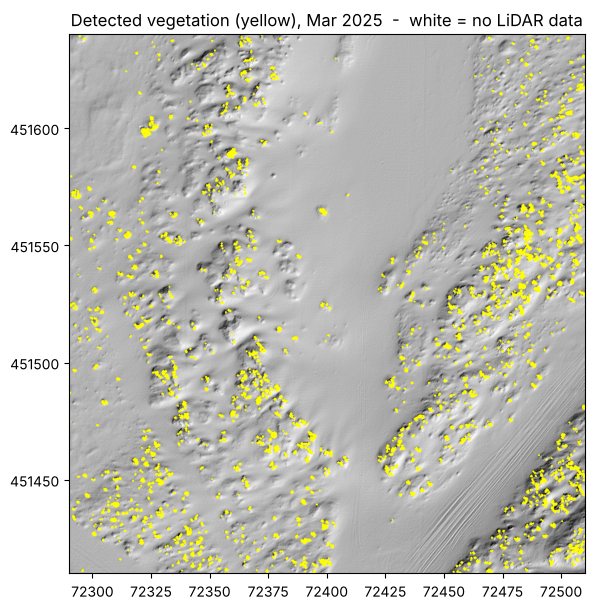

In [3]:
fig, ax = plt.subplots(figsize=(7, 7)); g = r["grid_dtm"]
ax.imshow(H.hillshade(r), extent=H.extent(g), cmap="gray")
from scipy.ndimage import binary_dilation
big = binary_dilation(H.cover(r), iterations=4)                                    # enlarged for display only
ax.imshow(np.ma.masked_where(~big, big), extent=H.extent(r["grid_fine"]), cmap="autumn", vmin=0, vmax=1)
ax.set_title(f"Detected vegetation (yellow), {H.EPOCH_LABEL[E]}  -  white = no LiDAR data"); H.save(fig, "B1_vegetation_map")

In [4]:
sl = np.kron(r["slope"], np.ones((5, 5)))[::2, ::2][:r["grid_fine"]["nr"], :r["grid_fine"]["nc"]]      # slope on the 0.10 m grid
ok = H.has_data(r); cls = pd.cut(pd.Series(sl[ok]), [-1, 5, 10, 20, 90], labels=["0-5", "5-10", "10-20", ">20"])
tab = pd.DataFrame({"cover_%": (100 * pd.Series(H.cover(r)[ok]).groupby(cls.values, observed=True).mean()).round(2),
                    "area_m2": (pd.Series(np.ones(ok.sum())).groupby(cls.values, observed=True).sum() * H.FINE_RES ** 2).round(0)})
H.table(tab.reset_index().rename(columns={"index": "slope (deg)"}), "B1_cover_vs_slope")

,slope (deg),cover_%,area_m2
0,0-5,0.47,30664.0
1,5-10,1.14,13237.0
2,10-20,2.01,6127.0
3,>20,2.47,573.0


**To write (B1):** the vegetation fraction, the map, and obvious misclassification: vegetation below ~10 cm is missed; steep slopes and wet or rough sand can give false detections (cover increases with slope in the table: real, or a slope artefact?); poles / people were removed by height and shape rules.

## B2 - Characterisation: tussock volume
Tussocks are found with DBSCAN on the vegetation points (points < 20 cm apart belong together). The intermediate quantity is the **canopy volume**, computed four ways: **column** (canopy height integrated over the footprint, closed at the base - main choice), **convex hull**, **voxels** and **alpha shape**.

In [5]:
vols = ["vol_column", "vol_hull", "vol_voxel", "vol_alpha"]
tot = t[vols].sum().to_frame("total volume (m3)").T.round(2); tot.insert(0, "tussocks", len(t)); H.table(tot, "B2_volume_totals")

,tussocks,vol_column,vol_hull,vol_voxel,vol_alpha
total volume (m3),687,78.07,149.46,6.56,15.07


,vol_column,vol_hull,vol_voxel,vol_alpha
vol_column,1.00,0.97,0.91,0.85
vol_hull,0.97,1.00,0.88,0.81
vol_voxel,0.91,0.88,1.00,0.88
vol_alpha,0.85,0.81,0.88,1.00


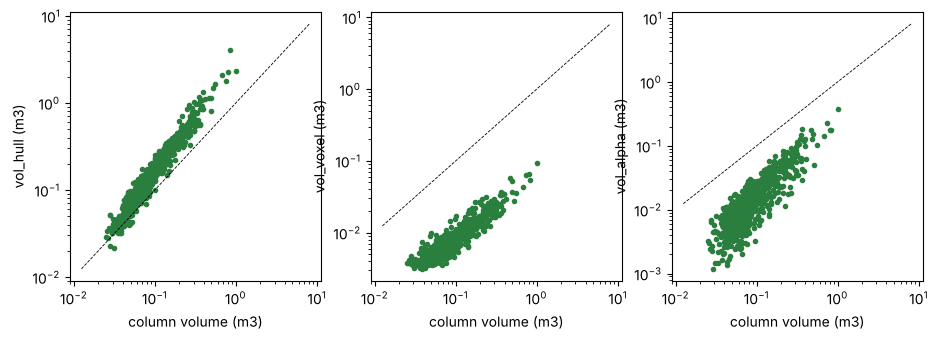

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, m in zip(axs, ["vol_hull", "vol_voxel", "vol_alpha"]):
    ax.loglog(t.vol_column, t[m], ".", c="#2a7f3f"); lim = [t.vol_column.min() / 2, t[vols].max().max() * 2]; ax.plot(lim, lim, "k--", lw=.6)
    ax.set_xlabel("column volume (m3)"); ax.set_ylabel(m + " (m3)")
H.save(fig, "B2_estimator_comparison"); t[vols].corr(method="spearman").round(2)

In [7]:
rows = []                                            # sensitivity to the key parameters
for vox in [0.03, 0.05, 0.10]:
    for ar in [0.10, 0.15, 0.25]:
        s = H.tussocks(r, voxel=vox, alpha_radius=ar); rows.append({"voxel (m)": vox, "alpha radius (m)": ar, "vol_voxel": s.vol_voxel.sum(), "vol_alpha": s.vol_alpha.sum(), "vol_column": s.vol_column.sum()})
H.table(pd.DataFrame(rows).round(2), "B2_sensitivity")

,voxel (m),alpha radius (m),vol_voxel,vol_alpha,vol_column
0,0.03,0.10,1.49,2.54,78.07
1,0.03,0.15,1.49,15.07,78.07
2,0.03,0.25,1.49,33.32,78.07
3,0.05,0.10,6.56,2.54,78.07
4,0.05,0.15,6.56,15.07,78.07
5,0.05,0.25,6.56,33.32,78.07
6,0.10,0.10,39.59,2.54,78.07
7,0.10,0.15,39.59,15.07,78.07
8,0.10,0.25,39.59,33.32,78.07


**To write (B2):** column volume is the main estimate (closed base, robust to the parameters); hull over-estimates (fills space between lobes); voxel and alpha volumes change by several times with their size parameter, so they are descriptors, not unbiased volumes (see the sensitivity table).

## B3 - Volume to biomass
**AGB = volume x rho.** rho (kg dry biomass per m3 of canopy volume) is set in `helpers.py` (`RHO`): **placeholder values** until fixed from literature / the manual samples (notebook C).

In [8]:
show = pd.concat([t.nlargest(1, "vol_column"), t.iloc[[len(t) // 2]], t.nsmallest(1, "vol_column")]).copy(); show["patch"] = ["largest", "medium", "smallest"]
H.table(show[["patch", "footprint_m2", "h_max", "vol_column", "agb_low_kg", "agb_mid_kg", "agb_high_kg"]].round(3), "B3_patches")

,patch,footprint_m2,h_max,vol_column,agb_low_kg,agb_mid_kg,agb_high_kg
447,largest,3.14,0.896,1.008,0.302,0.807,1.412
343,medium,0.92,0.430,0.219,0.066,0.175,0.306
288,smallest,0.14,0.249,0.025,0.007,0.020,0.035


**To write (B3):** where rho comes from and its assumptions (species, dry vs fresh mass, canopy density). Are the differences between the patches logical (bigger plant = more biomass; similar plants = similar kg per m2)?

## B4 - Uncertainty
Two blocks: **structure** (how tussocks are found / measured: DBSCAN distance, minimum points, minimum height) and **conversion** (rho). Every combination is run.

In [9]:
import itertools
rows = []
for eps, ms, mh in itertools.product([0.15, 0.20, 0.30], [5, 8, 12], [0.08, 0.10, 0.15]):
    s = H.tussocks(r, eps=eps, min_samples=ms, min_height=mh, alpha=False); rows.append({"eps": eps, "min_samples": ms, "min_height": mh, "tussocks": len(s), "volume_m3": s.vol_column.sum()})
sw = H.table(pd.DataFrame(rows).round(3), "B4_parameter_sweep")
base = t.vol_column.sum()
unc = pd.DataFrame({"low": [sw.volume_m3.min(), base * H.RHO["low"]], "base": [base, base * H.RHO["mid"]], "high": [sw.volume_m3.max(), base * H.RHO["high"]]},
                   index=["structure: volume (m3) over all parameter sets", "conversion: biomass (kg) for rho low / mid / high"]).round(2)
H.table(unc.reset_index(), "B4_uncertainty_budget")

,index,low,base,high
0,structure: volume (m3) over all parameter sets,23.29,78.07,96.56
1,conversion: biomass (kg) for rho low / mid / high,23.42,62.46,109.30


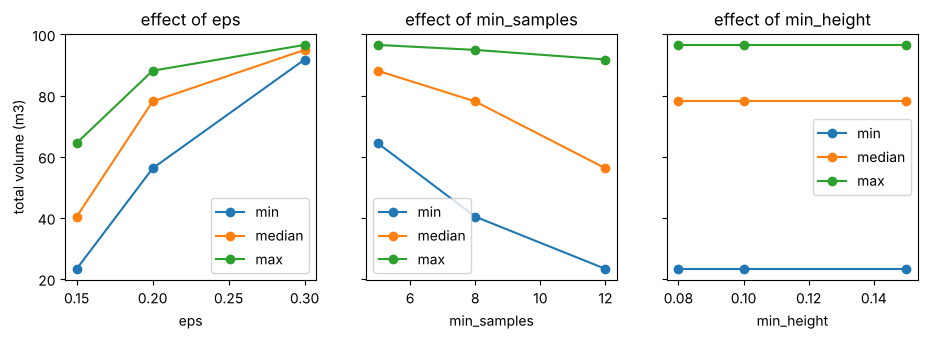

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, p in zip(axs, ["eps", "min_samples", "min_height"]):
    sw.groupby(p).volume_m3.agg(["min", "median", "max"]).plot(ax=ax, marker="o"); ax.set_title("effect of " + p)
axs[0].set_ylabel("total volume (m3)"); H.save(fig, "B4_parameter_effects")

**To write (B4):** which block dominates (compare the relative spread of the two rows) and what that means. Also name density / noise (structure) and species, moisture and dry vs fresh mass (conversion).